# FedFST POWER ve FedSPA ile Federe Graf Öğrenmesi
**İleri Yapay Zeka · WarmUP Ödev 2 · Enes Can · 20 Ekim 2026**

Bu defter, FedFST'ın kaynak kodunu çalıştırır ve aynı Cora, Citeseer, Actor,
Minesweeper ve Squirrel verileri üzerinde POWER ve FedSPA ile karşılaştırır.
Kurulum, kaynak sürümleri, gerekli uyarlamalar, veri bölmeleri, eğitim çıktıları ve
değerlendirme kodu defterin içindedir. **Çalışma zamanı → Tümünü çalıştır** ile baştan yürütülebilir.

Ödev metninin ilk cümlesinde MemGraphRAG adı geçmektedir; verilen GitHub bağlantısı
ve yapılacaklar bölümü FedFST'ı istediği için uygulama FedFST üzerine kurulmuştur.

## 1 Yöntemlerin çalışma mantığı

| Yöntem | Temel yaklaşım | Bu defterde kullanılan resmî kaynak |
|---|---|---|
| FedFST | Eski görevlerdeki yüksek frekans bilgisini sentetik graf üzerinden geri kazandırır (HHKR); düşük frekanslı anlam bilgisini damıtmayla aktarır (HLST). | [FedFST](https://github.com/YunQi572/FedFST) |
| POWER KDD 2025 | Yerel ve global temsilleri kullanarak kapsama dayalı deneyim belleği seçer; sunucuda prototip gradyanlarından örnekler oluşturur ve zamansal bilgi aktarımı yapar. | [Resmî Zenodo kod arşivi](https://zenodo.org/records/15487655), [makale](https://arxiv.org/abs/2411.18919) |
| FedSPA CVPR 2025 | Özellik yayılımını homofili durumuna göre ayırır (SFPD); homofili yanlılığı ve Fisher farklarına göre katmanları birleştirir (HBDA). | [FedSPA](https://github.com/OakleyTan/FedSPA), [makale](https://openaccess.thecvf.com/content/CVPR2025/html/Tan_FedSPA_Generalizable_Federated_Graph_Learning_under_Homophily_Heterogeneity_CVPR_2025_paper.html) |

FedFST ve POWER sürekli öğrenme yöntemleridir. FedSPA'nın özgün problemi statik
federe graf öğrenmesidir. Bu defterde özgün **ACM modeli ve Server.aggregate kodu**
aynı görev akışına uyarlanmıştır. Bu nedenle FedSPA satırları sürekli öğrenme
protokolüne uyarlanmış bir karşılaştırma yöntemini temsil eder.

## 2 Deney düzeni ve sınırlar

Graf, Louvain topluluklarıyla üç istemciye ayrılır. Her istemcide her sınıfın
düğümleri sabit tohumla yaklaşık %60 eğitim, %20 doğrulama ve %20 test olarak bölünür.
Yuvarlamadan kalan düğümler test bölümüne eklenir. Üç yöntem aynı kaydedilmiş bölmeleri
kullanır; SHA256 özetleri bu eşleşmeyi denetler. Çapraz istemci kenarları kullanılmaz.

Görevler etiket sırasıyla ikişer sınıftan oluşur. Son grupta tek sınıf kalırsa korunur;
böylece bütün sınıflar kullanılır. Cora 4, Citeseer 3, Actor 3, Squirrel 3 görev içerir.
Minesweeper iki sınıflı olduğu için tek görev içerir; bu veri setinde unutma metriği
tanımsızdır ve FedFST'ın eski göreve ilişkin üretici/damıtma aşaması tetiklenmez.
Modelin tahmin uzayı tüm sınıflardır; test sırasında görev etiketine göre logit maskelemesi yapılmaz.
Üç yöntemin sunucudaki global modeli değerlendirilir.

**Bu, makale tablolarının birebir yeniden üretimi değildir.** Colab'da uygulanabilir
bir WarmUP deneyi için tek tohum (24), görev başına 10 iletişim turu ve tur başına
3 yerel eğitim adımı kullanılır. FedFST'ın üretici ve damıtma eğitimi 200 yerine
20 epoch; sentetik örnek sayısı sınıf başına 16; graf ayarlama sınırı 20 iterasyondur.
POWER'ın prototip yeniden kurma bütçesi 300 yerine 20 LBFGS iterasyonudur.
FedSPA, 64 gizli boyut ve Adam 0.005 ile tam graf üzerinde çalışır; özgün
makaledeki 200 turluk mini-batch düzeninden farklıdır. FedFST/POWER GAT, FedSPA ACM
kullanır. Süreler CPU duvar saatidir ve yöntemlerin ek maliyetleri eşitlenmemiştir.
Tek tohumdan istatistiksel üstünlük veya makale performansına ulaşıldığı sonucu çıkarılmaz.

Etiketler yalnızca görev tanımlamak ve değerlendirmek için bütün düğümlerde mevcuttur;
eğitim kayıpları, üretici gerçek örnekleri ve Fisher hesapları yalnızca eğitim etiketlerini kullanır.
Doğrulama kümesi ayrılmıştır; bu sabit bütçeli koşuda hiperparametre araması yapılmaz.

## 3 Kurulum ve ortam

Standart Colab CPU çalışma zamanı yeterlidir. API anahtarı, Google Drive bağlama
veya ücretli GPU gerekmez. PyTorch mevcutsa korunur; diğer bağımlılıklar PyPI üzerinden yüklenir.
Çıktıda kullanılan gerçek sürümler ve donanım bilgisi kaydedilir.

In [20]:
import importlib.util, importlib.metadata, subprocess, sys, platform, json, os
from pathlib import Path
packages = ["torch-geometric==2.7.0", "python-louvain==0.16", "scikit-learn", "pandas", "matplotlib", "gdown", "ogb"]
if importlib.util.find_spec("torch") is None:
    packages.insert(0, "torch")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)
import torch, torch_geometric, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display as _rich_display, Markdown, Image
get_ipython().run_line_magic("matplotlib", "inline")
def display(value):
    # Dinamik HTML tablolarına ihtiyaç duymadan taşınabilir çıktı üret.
    if isinstance(value, pd.DataFrame):
        print(value.to_string())
    elif isinstance(value, Markdown):
        print(value.data.replace("**", ""))
    else:
        _rich_display(value)
environment = {"python":sys.version, "platform":platform.platform(), "torch":torch.__version__,
               "torch_geometric":torch_geometric.__version__, "cuda_available":torch.cuda.is_available(),
               "experiment_device":"CPU", "matplotlib_backend":plt.get_backend(), "execution_utc":pd.Timestamp.now(tz="UTC").isoformat(),
               "google_colab":bool(importlib.util.find_spec("google")) and bool(importlib.util.find_spec("google.colab")),
               "packages":{name:importlib.metadata.version(name) for name in ["numpy","pandas","networkx","python-louvain","scikit-learn","ogb"]}}
Path("environment.json").write_text(json.dumps(environment,indent=2))
print(json.dumps(environment, indent=2))
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,
                     "axes.spines.right":False,"axes.titleweight":"semibold"})
COLORS = {"FedFST":"#235789", "POWER":"#B97812", "FedSPA":"#8C4778"}

{
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cpu",
  "torch_geometric": "2.7.0",
  "cuda_available": false,
  "experiment_device": "CPU",
  "matplotlib_backend": "module://matplotlib_inline.backend_inline",
  "execution_utc": "2026-10-20T16:49:56.114249+00:00",
  "google_colab": true,
  "packages": {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "networkx": "3.7",
    "python-louvain": "0.16",
    "scikit-learn": "1.6.1",
    "ogb": "1.3.6"
  }
}


## 4 Kaynak kodların hazırlanması ve uyarlamalar

Kaynak sürümleri sabitlenmiştir. POWER'ın GitHub adresi erişilemediği için makalenin
resmî Zenodo sürümü indirilir ve arşivin MD5 özeti doğrulanır.

Çalıştırma için gereken değişiklikler şunlardır:

1. FedFST'ta tanımlı olmayan ve kullanılmayan `edge_distribution_low1/2` içe aktarımları kaldırılır.
   Kullanılmayan `torch_sparse` bağımlılığı kaldırılır; paket dizinleri açıkça tanımlanır.
   Giriş betiğindeki eksik parametreler, sınıfları doğrudan çağıran deney çalıştırıcısında tamamlanır.
2. Son eksik sınıf grubu atılmaz. Ortak veri yükleyici, özgün FedFST yükleyicisinde bulunmayan
   Minesweeper ve Squirrel'ı PyG üzerinden ekler. Test ve doğrulama örnekleri üreticiye verilmez.
   Damıtma sonrasında global ağırlıklar tekrar yayımlanır.
3. POWER'da bool düğüm maskesini indis gibi kullanan `edge_masking` düzeltilir.
   GAT kendi öz döngülerini ekler. OpenFGL'nin kullanılan tek maske yardımcısı deftere alınır;
   300 denemelik Optuna araması yerine özgün istemci ve sunucu sınıfları doğrudan çalıştırılır.
4. FedSPA'nın özgün model ve birleştirme tanımları AST ile kaynak dosyadan yüklenir.
   Eksik giriş yapılandırması ve FLGo dosya üretimi yerine ortak görevler kullanılır.
   DGL'nin altı tür komşu toplama işlemi eşdeğer PyTorch COO `index_add_` işlemleriyle yürütülür.
   Sıfır/toplamı sabit ağırlıklar için nötr normalizasyon eklenir; Fisher yalnızca eğitim
   etiketlerinde hesaplanır. HBDA yanlılığı, istemci spektral enerjisinin ağırlıklı ortalamadan
   uzaklığı olarak her yeni görev için hesaplanır. Bu uyarlamalar aşağıdaki kodda görülebilir.

FedFST'ın kayıpları ve POWER'ın yeniden kurma/bellek mantığı kaynak uygulamalardan kullanılır.
FedSPA'nın model ve birleştirme denklemleri korunur; çalışma altyapısı ve görev protokolü uyarlanır.

### Kaynak indirme ve yama kodu

In [21]:
%%writefile prepare_sources.py
"""Kaynak sürümlerini indirir ve belgelenmiş çalıştırılabilirlik yamalarını uygular."""
from pathlib import Path
import hashlib
import json
import urllib.request
import zipfile
import shutil

SOURCES = {
    "FedFST": ("https://github.com/YunQi572/FedFST", "d83fac0eff2ebf764d5574997a5fec0abf9cc2c7"),
    "FedSPA": ("https://github.com/OakleyTan/FedSPA", "d2b3ddb8f853a8d78c120407eba6c1a44127bc33"),
}

def prepare_sources(root):
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    manifest = {}
    for name, (url, revision) in SOURCES.items():
        target = root / name
        if not target.exists():
            archive = root / (name + ".zip")
            urllib.request.urlretrieve(f"{url}/archive/{revision}.zip", archive)
            with zipfile.ZipFile(archive) as z:
                z.extractall(root)
                shutil.move(str(root / z.namelist()[0].split('/')[0]), target)
        manifest[name] = {"url": url, "revision": revision}
    power = root / "POWER"
    if not (power / "flcore").exists():
        archive = root / "POWER.zip"
        urllib.request.urlretrieve(
            "https://zenodo.org/api/records/15487655/files/zyl24/FCGL_POWER-official.zip/content", archive)
        assert hashlib.md5(archive.read_bytes()).hexdigest() == "567faa826ad62a3d8610682ee2e8474f"
        with zipfile.ZipFile(archive) as z:
            folder = z.namelist()[0].split('/')[0]
            z.extractall(root / "power_extract")
        if power.exists():
            shutil.rmtree(power)
        shutil.move(str(root / "power_extract" / folder), power)
    manifest["POWER"] = {"url": "https://zenodo.org/records/15487655",
                         "revision": "78e30b6", "md5": "567faa826ad62a3d8610682ee2e8474f"}

    # Kullanılmayan, depoda tanımlanmamış fonksiyonları içe aktarma hatası.
    ours = root / "FedFST/algorithm/Ours.py"
    text = ours.read_text().replace(
        ", edge_distribution_low1, edge_distribution_low2", "")
    # Eski sınıfların üreticisinde sadece eğitim verisinin özellikleri/etiketleri kullanılır.
    text = text.replace('task_data["train_mask"] | task_data["valid_mask"] | task_data["test_mask"]',
                        'task_data["train_mask"]')
    text = text.replace('task["train_mask"] | task["valid_mask"] | task["test_mask"]',
                        'task["train_mask"]')
    ours.write_text(text)
    for package in ("datasets", "models", "algorithm"):
        (root / "FedFST" / package / "__init__.py").touch()
    loader = root / "FedFST/datasets/dataset_loader.py"
    text = loader.read_text().replace("from torch_sparse import SparseTensor", "# Unused optional torch_sparse import removed")
    # Son grupta tek sınıf varsa onu da koru. Tüm veri setlerinin tüm sınıfları kullanılır.
    text = text.replace("if drop_flag:\n        tasks_num = tasks_num - 1", "if False:  # keep the final incomplete class group\n        tasks_num = tasks_num - 1")
    loader.write_text(text)

    # POWER'ın bool maskeyi düğüm indisleri gibi yineleyen yardımcı fonksiyonunu düzelt.
    utils = power / "utils.py"
    text = utils.read_text()
    start = text.index("def edge_masking(")
    end = text.index("\ndef accuracy(", start)
    text = text[:start] + '''def edge_masking(edge_index, handled, device):
    handled = handled.to(device).bool()
    keep = handled[edge_index[0]] & handled[edge_index[1]]
    return coalesce(edge_index[:, keep])

''' + text[end:]
    utils.write_text(text)
    # OpenFGL'den yalnızca bu 4 satırlık maske yardımcısı kullanılıyor.
    ours = power / "flcore/Ours.py"
    text = ours.read_text().replace("from openfgl.utils.basic_utils import idx_to_mask_tensor", '''def idx_to_mask_tensor(indices, size):
    mask = torch.zeros(size, dtype=torch.bool)
    mask[indices] = True
    return mask''')
    ours.write_text(text)
    (root / "source_manifest.json").write_text(json.dumps(manifest, indent=2))
    return manifest

Overwriting prepare_sources.py


### Ortak veri ve değerlendirme kodu

In [22]:
%%writefile experiment_common.py
"""Ortak veri bölmeleri, görevler ve değerlendirme. Test verisi eğitimde kullanılmaz."""
from pathlib import Path
import copy
import hashlib
import json
import random
import numpy as np
import torch
from torch_geometric.data import Data
from torch_geometric.datasets import Planetoid, Actor, HeterophilousGraphDataset, WikipediaNetwork
from torch_geometric.utils import subgraph, to_undirected
import networkx as nx
from community import community_louvain

DATASETS = ["cora", "citeseer", "actor", "minesweeper", "squirrel"]

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(1)

def task_graph(data, mask):
    edges, _ = subgraph(mask, data.edge_index, relabel_nodes=False, num_nodes=data.num_nodes)
    return Data(x=data.x, y=data.y, edge_index=edges)

def make_tasks(data, classes_per_task=2, seed=24):
    rng = np.random.default_rng(seed)
    masks = [torch.zeros(data.num_nodes, dtype=torch.bool) for _ in range(3)]
    classes = int(data.y.max()) + 1
    for label in range(classes):
        ids = torch.where(data.y == label)[0].numpy()
        rng.shuffle(ids)
        n = len(ids)
        a, b = int(n * .6), int(n * .8)
        masks[0][ids[:a]] = True
        masks[1][ids[a:b]] = True
        masks[2][ids[b:]] = True
    tasks = []
    for first in range(0, classes, classes_per_task):
        handled = (data.y >= first) & (data.y < first + classes_per_task)
        tasks.append({"train_mask": masks[0] & handled,
                      "valid_mask": masks[1] & handled,
                      "test_mask": masks[2] & handled,
                      "local_data": task_graph(data, handled)})
    return tasks

def prepare_dataset(name, root, seed=24, clients=3):
    root = Path(root)
    seed_all(seed)
    raw = root / "raw" / name
    if name in ("cora", "citeseer"):
        data = Planetoid(str(raw), name)[0]
    elif name == "actor":
        data = Actor(str(raw))[0]
    elif name == "minesweeper":
        data = HeterophilousGraphDataset(str(raw), name)[0]
    else:
        data = WikipediaNetwork(str(raw), name="squirrel", geom_gcn_preprocess=True)[0]
    data.edge_index = to_undirected(data.edge_index, num_nodes=data.num_nodes)
    data.x = data.x.float()
    data.y = data.y.long().view(-1)
    classes = int(data.y.max()) + 1
    graph = nx.Graph()
    graph.add_nodes_from(range(data.num_nodes))
    graph.add_edges_from(data.edge_index.T.tolist())
    partition = community_louvain.best_partition(graph, random_state=seed)
    communities = {}
    for node, group in partition.items():
        communities.setdefault(group, []).append(node)
    groups = [[] for _ in range(clients)]
    for nodes in sorted(communities.values(), key=len, reverse=True):
        groups[min(range(clients), key=lambda i: len(groups[i]))].extend(nodes)
    client_data, tasks = [], []
    for i, nodes in enumerate(groups):
        ids = torch.tensor(sorted(nodes))
        edge, _ = subgraph(ids, data.edge_index, relabel_nodes=True, num_nodes=data.num_nodes)
        local = Data(x=data.x[ids].clone(), y=data.y[ids].clone(), edge_index=edge)
        local.global_ids = ids
        local_tasks = make_tasks(local, seed=seed + i)
        # Bir sınıfın bir istemcide bulunmaması tüm istemcilerde görev sayısını değiştirmez.
        while len(local_tasks) < (classes + 1) // 2:
            empty = torch.zeros(local.num_nodes, dtype=torch.bool)
            local_tasks.append({"train_mask": empty.clone(), "valid_mask": empty.clone(),
                               "test_mask": empty.clone(), "local_data": task_graph(local, empty)})
        client_data.append(local)
        tasks.append(local_tasks)
    fingerprints = []
    for local, local_tasks in zip(client_data, tasks):
        for task in local_tasks:
            train, valid, test = [task[k] for k in ("train_mask", "valid_mask", "test_mask")]
            assert not (train & valid).any() and not (train & test).any() and not (valid & test).any()
            fingerprints.append(torch.stack([train, valid, test]).numpy().tobytes())
    split_hash = hashlib.sha256(b"".join(fingerprints)).hexdigest()
    payload = {"clients": client_data, "tasks": tasks, "classes": classes,
               "input_dim": data.num_features, "dataset": name, "seed": seed,
               "split_sha256": split_hash}
    root.mkdir(parents=True, exist_ok=True)
    torch.save(payload, root / f"{name}_{seed}.pt")
    return {"Veri seti": name, "Düğüm": data.num_nodes, "Kenar yönlü": data.num_edges,
            "Özellik": data.num_features, "Sınıf": classes, "Görev": (classes + 1) // 2,
            "İstemci düğümleri": [x.num_nodes for x in client_data], "Bölme SHA256": split_hash}

def read_payload(root, name, seed):
    return torch.load(Path(root) / f"{name}_{seed}.pt", map_location="cpu", weights_only=False)

def evaluate_matrix_row(clients, tasks, predict, stage):
    row = []
    for t in range(stage + 1):
        correct = total = 0
        for i in range(len(clients)):
            mask = tasks[i][t]["test_mask"]
            if int(mask.sum()) == 0:
                continue
            pred = predict(i, t).detach().cpu().argmax(-1)
            labels = clients[i].y.cpu()
            correct += int((pred[mask] == labels[mask]).sum())
            total += int(mask.sum())
        assert total > 0, f"Task {t}: test nodes missing"
        row.append(100 * correct / total)
    return row

def save_result(method, payload, matrix, elapsed, root, settings, history=None):
    matrix = np.asarray(matrix, dtype=float)
    n = matrix.shape[0]
    aa = float(matrix[-1].mean())
    af = float(np.mean(np.diag(matrix)[:-1] - matrix[-1, :-1])) if n > 1 else None
    result = {"method": method, "dataset": payload["dataset"], "seed": payload["seed"],
              "AA_percent": aa, "AF_percentage_points": af, "seconds": elapsed,
              "matrix": matrix.tolist(), "split_sha256": payload["split_sha256"],
              "settings": settings, "history": history or []}
    assert np.isfinite(matrix[np.tril_indices(n)]).all()
    output = Path(root) / f'{method}_{payload["dataset"]}_{payload["seed"]}.json'
    output.parent.mkdir(parents=True, exist_ok=True)
    output.write_text(json.dumps(result, indent=2))
    print(json.dumps({k:v for k,v in result.items() if k not in ("history", "settings")}, indent=2), flush=True)
    return result

Overwriting experiment_common.py


### Yöntemleri çalıştıran uyarlama kodu

In [23]:
%%writefile run_experiment.py
"""Üç resmî uygulamayı aynı veri ve görevlerle çalıştıran ince uyarlama katmanı."""
import argparse
import ast
import collections
import copy
from pathlib import Path
import sys
import time
from types import SimpleNamespace
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import init
from torch.nn.parameter import Parameter
from torch.nn.modules.module import Module
from torch_geometric.utils import add_self_loops, degree, subgraph
from experiment_common import read_payload, seed_all, evaluate_matrix_row, save_result

def execute_selected(path, names, namespace):
    """Seçilen tanımları kaynak dosyadan aynen yükle; yan etkili giriş betiğini çalıştırma."""
    tree = ast.parse(Path(path).read_text())
    chosen = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.ClassDef)) and n.name in names]
    assert {n.name for n in chosen} == set(names), path
    exec(compile(ast.Module(body=chosen, type_ignores=[]), str(path), "exec"), namespace)

def run_fedfst(cfg, payload):
    sys.path.insert(0, str(Path(cfg.sources) / "FedFST"))
    from args import parser
    from algorithm.Ours import OursClient, OursServer
    args = parser.parse_args([])
    args.input_dim, args.output_dim = payload["input_dim"], payload["classes"]
    args.clients_num, args.device_id, args.use_gpu = 3, 0, False
    args.rounds, args.local_epochs = cfg.rounds, cfg.local_epochs
    args.gen_epochs, args.kd_epochs = cfg.gen_epochs, cfg.kd_epochs
    args.gen_rounds = 2
    args.gen_num_samples_per_class = 16
    args.num_samples_per_class = 16
    args.max_iterations = 20
    args.shuffle_flag = False
    # Kaynakta getattr ile kullanılan fakat parser'da bulunmayan parametreler.
    args.gen_ce_weight, args.kd_ce_weight = 1.0, .5
    args.seed = cfg.seed
    # Erken durdurma/epoch seçimi test kümesine erişmeden sabit bütçeyle yapılır.
    args.kd_eval_start_epoch = cfg.kd_epochs + 1
    device = torch.device("cpu")
    pool = {}
    server = OursServer(args, pool, device)
    clients = [OursClient(args, i, d, pool, device, list(range(payload["classes"])))
               for i, d in enumerate(payload["clients"])]
    for i, client in enumerate(clients):
        client.tasks = copy.deepcopy(payload["tasks"][i])
    server.set_clients(clients)
    server.send_message()
    count = len(payload["tasks"][0])
    matrix = np.full((count, count), np.nan)
    history = []
    for task in range(count):
        for r in range(cfg.rounds):
            losses = []
            for c in clients:
                if int(c.tasks[task]["train_mask"].sum()) > 0:
                    losses.append(c.train(task))
                c.send_message(task)
                if int(c.tasks[task]["train_mask"].sum()) == 0:
                    pool[f"client_{c.client_id}"]["nodes_num"] = 0
            server.aggregate()
            server.send_message()
            history.append({"task": task, "round": r, "loss": float(np.mean(losses))})
        if task:
            server.feature_gen_init(task)
            for c in clients:
                c.feature_gen_init(task)
            for r in range(args.gen_rounds):
                for c in clients:
                    c.feature_gen_train(task, r != 0)
                    c.send_feature_gen(task)
                server.feature_gen_aggregate()
                server.send_feature_gen()
            server.KD_train(task)
            server.send_message()  # Son damıtılmış global ağı değerlendirmeye ve sonraki göreve gönder.
        server.update_last_global_model()
        for c in clients:
            c.last_global_model.load_state_dict(server.last_global_model.state_dict())
        def predict(i, t):
            server.global_model.eval()
            with torch.no_grad():
                return server.global_model(clients[i].tasks[t]["local_data"])[1]
        matrix[task, :task+1] = evaluate_matrix_row(payload["clients"], payload["tasks"], predict, task)
        print("FedFST task", task, matrix[task, :task+1], flush=True)
    return matrix, vars(args), history

def run_power(cfg, payload):
    sys.path.insert(0, str(Path(cfg.sources) / "POWER"))
    original_argv = sys.argv
    sys.argv = [sys.argv[0]]
    from config import parser
    sys.argv = original_argv
    from flcore.Ours import OursClient, OursServer
    args = parser.parse_args([])
    args.input_dim, args.output_dim = payload["input_dim"], payload["classes"]
    args.num_rounds_per_task, args.num_epochs = cfg.rounds, cfg.local_epochs
    args.num_it_recon = cfg.recon_iterations
    args.num_epoch_g = 3
    args.seed = cfg.seed
    args.task_dir = str(Path(cfg.results) / "power_cache" / f'{cfg.dataset}_{cfg.seed}')
    Path(args.task_dir).mkdir(parents=True, exist_ok=True)
    # Önbellek eski bölmelerle karışmasın.
    for path in Path(args.task_dir).glob("*.pt"):
        path.unlink()
    device = torch.device("cpu")
    pool = {}
    data = []
    for local, tasks in zip(payload["clients"], payload["tasks"]):
        mapped = []
        for task in tasks:
            mapped.append({"train_mask": task["train_mask"], "val_mask": task["valid_mask"],
                           "test_mask": task["test_mask"]})
        data.append({"data": local, "task": mapped})
    clients = [OursClient(args, i, d, pool, device) for i, d in enumerate(data)]
    server = OursServer(args, pool, device)
    count = len(data[0]["task"])
    matrix = np.full((count, count), np.nan)
    for task in range(count):
        pool["task_id"] = task
        for r in range(cfg.rounds):
            pool["round_id"] = r
            server.send_message()
            for c in clients:
                c.execute(task)
                c.send_message(task)
            server.execute()
        server.send_message()
        def predict(i, t):
            graph = clients[i].task_data(t, data[i]["data"], data[i]["task"][t])
            server.global_model.eval()
            with torch.no_grad():
                return server.global_model(graph)[0]
        matrix[task, :task+1] = evaluate_matrix_row(payload["clients"], payload["tasks"], predict, task)
        for c in clients:
            c.task_done(task)
        print("POWER task", task, matrix[task, :task+1], flush=True)
    return matrix, vars(args), []

class TorchBlock:
    """FedSPA'nın DGL sum-reducer işleminin eşdeğer PyTorch COO uygulaması."""
    def __init__(self, data):
        self.data = data
        self.srcdata = {}
        self.dstdata = {}

    def update_all(self, message_func, reduce_func):
        src, dst = self.data.edge_index
        labels = torch.full_like(self.data.y, -1)
        labels[self.data.train_mask] = self.data.y[self.data.train_mask]
        known = (labels[src] >= 0) & (labels[dst] >= 0)
        kinds = {"hete": known & (labels[src] != labels[dst]),
                 "homo": known & (labels[src] == labels[dst]), "unk": ~known}
        for frequency in ("low", "high"):
            h = self.srcdata["h_" + frequency]
            for kind, keep in kinds.items():
                result = torch.zeros_like(h)
                result.index_add_(0, dst[keep], h[src[keep]])
                self.dstdata[f"neigh_{kind}_{frequency}"] = result

def spa_operators(data):
    n = data.num_nodes
    edge, _ = add_self_loops(data.edge_index, num_nodes=n)
    values = torch.ones(edge.shape[1])
    a = torch.sparse_coo_tensor(edge, values, (n,n)).coalesce()
    rows = a.indices()[0]
    deg = torch.zeros(n).scatter_add_(0, rows, a.values())
    low = torch.sparse_coo_tensor(a.indices(), a.values() / deg[rows].clamp_min(1), (n,n)).coalesce()
    ids = torch.arange(n).repeat(2,1)
    high = torch.sparse_coo_tensor(torch.cat([ids, low.indices()], 1),
                                 torch.cat([torch.ones(n), -low.values()]), (n,n)).coalesce()
    un = torch.sparse_coo_tensor(data.edge_index, torch.ones(data.num_edges), (n,n)).coalesce()
    return un, low, high

class SPAWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, *args):
        return self.model(*args)
    def has_nan(self):
        return any(not torch.isfinite(p).all() for p in self.parameters())

def run_fedspa(cfg, payload):
    import math
    # FLGo'nun dosya üretimi ve CUDA/DGL bağımlılığı yerine aynı model ve Server.aggregate yüklenir.
    ns = dict(globals(), math=math, device=torch.device("cpu"))
    base = Path(cfg.sources) / "FedSPA/Code/benchmark001"
    execute_selected(base / "base.py", ["Seq", "MLP_spa"], ns)
    execute_selected(base / "config.py", ["freeze_parameters", "GraphConvolution", "ACM", "get_spa"], ns)
    ns["convert_to_dglgraph"] = lambda data: TorchBlock(data)
    ns["assign_pseudo_labels_to_dglgraph"] = lambda graph, ids, labels: graph
    ns["create_block_from_dglgraph"] = lambda graph: graph
    ns["mp_func_spa"] = ns["agg_func_spa"] = None
    ns["BasicServer"] = object
    definitions = ["sum_of_layer_fisher_differences", "normalize_list", "calculate_fisher_average",
                   "normalize", "calculate_weights", "fish_cal", "Server"]
    execute_selected(Path(cfg.sources) / "FedSPA/Code/flgo/algorithm/fedspa.py", definitions, ns)
    # Sabit vektör/0 toplamında bölüm belirsizliği için nötr ağırlıklar.
    ns["normalize"] = lambda x: [(float(v) - min(map(float,x))) / (max(map(float,x)) - min(map(float,x)))
                                  for v in x] if max(map(float,x)) > min(map(float,x)) else [0.0] * len(x)
    ns["normalize_list"] = lambda x: [v / sum(x) for v in x] if float(sum(x)) else [1 / len(x)] * len(x)
    # Fisher bilgisi yalnızca eğitim etiketlerinden hesaplanır.
    def fisher(net, data, un, low, high, high_list, low_list, mlp_list):
        net.zero_grad()
        out = net(data, un, low, high, high_list, low_list, mlp_list)
        F.nll_loss(out[data.train_mask], data.y[data.train_mask]).backward()
        return {name: p.grad.detach().clone().square() for name,p in net.named_parameters() if p.grad is not None}
    ns["fish_cal"] = fisher
    model = SPAWrapper(ns["get_spa"](payload["input_dim"], 64, payload["classes"], 2))
    server = ns["Server"]()
    server.model = model
    count = len(payload["tasks"][0])
    matrix = np.full((count,count), np.nan)
    history = []
    for task in range(count):
        active, operators = [], []
        for i, tasks in enumerate(payload["tasks"]):
            graph = copy.deepcopy(tasks[task]["local_data"])
            graph.train_mask = tasks[task]["train_mask"]
            if not int(graph.train_mask.sum()):
                continue
            ops = spa_operators(graph)
            operators.append(ops)
            # Kaynaktaki spektral özellik enerjisi, yoğun Laplasyen oluşturmadan hesaplanır.
            rng = np.random.RandomState(cfg.seed + i + task)
            ids = rng.choice(graph.num_features, max(1,int(.2*graph.num_features)), replace=False)
            x = graph.x[:,ids]
            src,dst = graph.edge_index
            dx = degree(src, graph.num_nodes).view(-1,1) * x
            ax = torch.zeros_like(x).index_add_(0, src, x[dst])
            den = x.square().sum(0)
            energy = float(((x*(dx-ax)).sum(0)[den>0] / den[den>0]).mean()) if (den>0).any() else 0.
            active.append(SimpleNamespace(train_data=SimpleNamespace(data=graph), datavol=int(graph.train_mask.sum()),
                                          adj_low_un=ops[0], adj_low=ops[1], adj_high=ops[2], radio_diff=energy))
        mean_energy = sum(c.radio_diff*c.datavol for c in active) / sum(c.datavol for c in active)
        for c in active:
            c.radio_diff = abs(c.radio_diff - mean_energy)
        server.clients = active
        server.received_clients = list(range(len(active)))
        if hasattr(server,"diffs"):
            del server.diffs
        for r in range(cfg.rounds):
            locals_ = []
            losses = []
            for c, ops in zip(active, operators):
                local = copy.deepcopy(server.model)
                local.train()
                c.fr_low_g_list = [layer.att_vec_low_unk for layer in local.model.gcns]
                c.fr_high_g_list = [layer.att_vec_high_unk for layer in local.model.gcns]
                c.mlp_list = [layer.att_vec_mlp for layer in local.model.gcns]
                optimizer = torch.optim.Adam(local.parameters(), lr=.005, weight_decay=5e-4)
                graph = c.train_data.data
                for _ in range(cfg.local_epochs):
                    optimizer.zero_grad()
                    out = local(graph, *ops, c.fr_high_g_list, c.fr_low_g_list, c.mlp_list)
                    loss = F.nll_loss(out[graph.train_mask], graph.y[graph.train_mask])
                    loss.backward()
                    optimizer.step()
                losses.append(float(loss))
                locals_.append(local)
            server.model = server.aggregate(locals_)
            history.append({"task":task,"round":r,"loss":float(np.mean(losses))})
        def predict(i,t):
            graph = copy.deepcopy(payload["tasks"][i][t]["local_data"])
            graph.train_mask = payload["tasks"][i][t]["train_mask"]
            server.model.eval()
            with torch.no_grad():
                return server.model(graph, *spa_operators(graph))
        matrix[task,:task+1] = evaluate_matrix_row(payload["clients"], payload["tasks"], predict, task)
        print("FedSPA task",task,matrix[task,:task+1],flush=True)
    return matrix, {"rounds":cfg.rounds,"local_epochs":cfg.local_epochs,"hidden_dim":64,
                    "learning_rate":.005,"backend":"PyTorch COO equivalent of DGL sum-reducer",
                    "protocol":"class incremental adapter; original model and Server.aggregate"}, history

if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--method", choices=["FedFST","POWER","FedSPA"], required=True)
    parser.add_argument("--dataset", required=True)
    parser.add_argument("--seed", type=int, default=24)
    parser.add_argument("--sources", default="sources")
    parser.add_argument("--data", default="experiment_data")
    parser.add_argument("--results", default="results")
    parser.add_argument("--rounds", type=int, default=10)
    parser.add_argument("--local-epochs", type=int, default=3)
    parser.add_argument("--gen-epochs", type=int, default=20)
    parser.add_argument("--kd-epochs", type=int, default=20)
    parser.add_argument("--recon-iterations", type=int, default=20)
    cfg = parser.parse_args()
    seed_all(cfg.seed)
    payload = read_payload(cfg.data, cfg.dataset, cfg.seed)
    start = time.perf_counter()
    matrix, settings, history = {"FedFST":run_fedfst,"POWER":run_power,"FedSPA":run_fedspa}[cfg.method](cfg,payload)
    save_result(cfg.method,payload,matrix,time.perf_counter()-start,cfg.results,settings,history)

Overwriting run_experiment.py


In [24]:
from prepare_sources import prepare_sources
manifest = prepare_sources("sources")
display(pd.DataFrame(manifest).T)
print("Kaynaklar ve yamalar hazır.")

                                        url                                  revision                               md5
FedFST   https://github.com/YunQi572/FedFST  d83fac0eff2ebf764d5574997a5fec0abf9cc2c7                               NaN
FedSPA  https://github.com/OakleyTan/FedSPA  d2b3ddb8f853a8d78c120407eba6c1a44127bc33                               NaN
POWER   https://zenodo.org/records/15487655                                   78e30b6  567faa826ad62a3d8610682ee2e8474f
Kaynaklar ve yamalar hazır.


## 5 Veri setlerini hazırlama ve denetleme

Özgün grafın bütün düğümleri kullanılır. Yeni %60/%20/%20 bölmeleri üretildiği için
veri setlerinin paket içinde gelen hazır maskeleri kullanılmaz.
Squirrel, PyG `WikipediaNetwork(geom_gcn_preprocess=True)` sürümüdür.

In [25]:
from experiment_common import prepare_dataset, read_payload, DATASETS
SEED = 24
ROUNDS, LOCAL_EPOCHS = 10, 3
GEN_EPOCHS, KD_EPOCHS, RECON_ITERATIONS = 20, 20, 20
METHODS = ["FedFST", "POWER", "FedSPA"]
DATA_DIR, RESULTS_DIR = Path("experiment_data"), Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
rows = [prepare_dataset(name, DATA_DIR, SEED) for name in DATASETS]
metadata = pd.DataFrame(rows)
metadata.to_json("dataset_metadata.json",orient="records",force_ascii=False,indent=2)
display(metadata.drop(columns="Bölme SHA256"))
display(metadata[["Veri seti","Bölme SHA256"]])
for name in DATASETS:
    payload = read_payload(DATA_DIR,name,SEED)
    assert sum(x.num_nodes for x in payload["clients"]) == int(metadata.loc[metadata["Veri seti"]==name,"Düğüm"].iloc[0])
    for tasks in payload["tasks"]:
        for task in tasks:
            assert int(task["train_mask"].sum()) > 0, f"{name}: boş yerel eğitim görevi"
print("Düğüm kapsamı ve ayrık maskeler doğrulandı; tüm yerel görevlerde eğitim örneği var.")

     Veri seti  Düğüm  Kenar yönlü  Özellik  Sınıf  Görev   İstemci düğümleri
0         cora   2708        10556     1433      7      4     [903, 903, 902]
1     citeseer   3327         9104     3703      6      3  [1109, 1109, 1109]
2        actor   7600        53411      932      5      3  [2534, 2533, 2533]
3  minesweeper  10000        78804        7      2      1  [3407, 3172, 3421]
4     squirrel   5201       396846     2089      5      3  [1724, 1729, 1748]
     Veri seti                                                      Bölme SHA256
0         cora  7f4e5f7cde4604a0790aceb1696e5c3f8f58edfe2f864016304592b6db15b1bb
1     citeseer  0237f9442400111192ede7e951d1b53172bbd415b51552b3b1dfa4a013a0f0ff
2        actor  5c1997908be5525d098d3bb98e6922b35da5e3247c76c5ccc3a797e313c2a8c2
3  minesweeper  b43c6e9082be598db12499817ff361682d1ff9df4e0cc09b2c37c4d29f39d6c8
4     squirrel  30f7c52e1b16782ef32a1518791380c2f4a348ada9f651d7ed4747b9645b451b
Düğüm kapsamı ve ayrık maskeler doğrulandı; tü

## 6 Eğitim ve gerçek deney çıktıları

Her yöntem ayrı Python işleminde çalışır; aynı adlı kaynak modüllerinin birbirine
karışması önlenir. Ayrıntılı eğitim günlükleri `logs/` altında saklanır; hücrelerde
görev doğrulukları ve son metrikler gösterilir. Bir işlem hata verirse defter durur.
Önceki sonuçlar yalnızca aynı ayarlar ve bölme özetiyle eşleşiyorsa tekrar kullanılabilir.

In [26]:
REUSE_MATCHING_RESULTS = True
Path("logs").mkdir(exist_ok=True)
def run_dataset(name):
    payload = read_payload(DATA_DIR,name,SEED)
    summaries = []
    for method in METHODS:
        target = RESULTS_DIR / f"{method}_{name}_{SEED}.json"
        cached = json.loads(target.read_text()) if target.exists() else None
        settings = cached.get("settings",{}) if cached else {}
        same_budget = (settings.get("rounds",settings.get("num_rounds_per_task")) == ROUNDS and
                       settings.get("local_epochs",settings.get("num_epochs")) == LOCAL_EPOCHS)
        if method == "FedFST":
            same_budget = same_budget and settings.get("gen_epochs")==GEN_EPOCHS and settings.get("kd_epochs")==KD_EPOCHS
        if method == "POWER":
            same_budget = same_budget and settings.get("num_it_recon")==RECON_ITERATIONS
        reusable = (REUSE_MATCHING_RESULTS and cached and same_budget and
                    cached["split_sha256"] == payload["split_sha256"])
        if not reusable:
            command = [sys.executable,"run_experiment.py","--method",method,"--dataset",name,
                       "--seed",str(SEED),"--rounds",str(ROUNDS),"--local-epochs",str(LOCAL_EPOCHS),
                       "--gen-epochs",str(GEN_EPOCHS),"--kd-epochs",str(KD_EPOCHS),
                       "--recon-iterations",str(RECON_ITERATIONS)]
            log = Path("logs") / f"{method}_{name}_{SEED}.log"
            print(f"{method} · {name} eğitiliyor...",flush=True)
            with log.open("w") as stream:
                run = subprocess.run(command,stdout=stream,stderr=subprocess.STDOUT)
            if run.returncode:
                print(log.read_text()[-6000:])
                raise RuntimeError(f"{method}/{name} başarısız; ayrıntılar {log}")
        result = json.loads(target.read_text())
        print(f'{method}: görev doğruluk matrisi (%)')
        display(pd.DataFrame(result["matrix"],index=[f"Aşama {i+1}" for i in range(len(result["matrix"]))],
                             columns=[f"Görev {i+1}" for i in range(len(result["matrix"]))]).round(2))
        summaries.append({"Yöntem":method,"AA (%)":result["AA_percent"],
                          "AF (yüzde puan)":result["AF_percentage_points"],"Süre (sn)":result["seconds"]})
    display(pd.DataFrame(summaries).round(2))

### Cora

In [27]:
run_dataset("cora")

FedFST: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3  Görev 4
Aşama 1    94.83      NaN      NaN      NaN
Aşama 2    54.31    97.59      NaN      NaN
Aşama 3    17.24     5.62    98.65      NaN
Aşama 4     0.00     0.00     0.00    100.0
POWER: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3  Görev 4
Aşama 1    95.69      NaN      NaN      NaN
Aşama 2    95.69     0.00      NaN      NaN
Aşama 3    96.55    38.96     0.00      NaN
Aşama 4    62.07    18.47     0.68      0.0
FedSPA: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3  Görev 4
Aşama 1    79.31      NaN      NaN      NaN
Aşama 2     0.00    85.94      NaN      NaN
Aşama 3     0.00     0.00    96.62      NaN
Aşama 4     0.00     0.00     0.00    100.0
   Yöntem  AA (%)  AF (yüzde puan)  Süre (sn)
0  FedFST    25.0            97.02      46.96
1   POWER    20.3             4.82      19.03
2  FedSPA    25.0            87.29      31.78


### Citeseer

In [28]:
run_dataset("citeseer")

FedFST: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    78.03      NaN      NaN
Aşama 2    67.63    80.07      NaN
Aşama 3     0.00     0.00    93.27
POWER: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    76.88      NaN      NaN
Aşama 2    64.16     0.00      NaN
Aşama 3    39.31    54.35      0.0
FedSPA: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    80.35      NaN      NaN
Aşama 2     1.73    86.23      NaN
Aşama 3     1.73     0.00    90.58
   Yöntem  AA (%)  AF (yüzde puan)  Süre (sn)
0  FedFST   31.09            79.05      40.02
1   POWER   31.22            -8.39      34.96
2  FedSPA   30.77            82.42      60.17


### Actor

In [29]:
run_dataset("actor")

FedFST: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    60.54      NaN      NaN
Aşama 2     0.00    53.11      NaN
Aşama 3     0.00     0.00    100.0
POWER: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    60.09      NaN      NaN
Aşama 2    43.54     0.00      NaN
Aşama 3    17.91    41.39      0.0
FedSPA: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    60.09      NaN      NaN
Aşama 2     0.00    51.81      NaN
Aşama 3     0.00     0.00    100.0
   Yöntem  AA (%)  AF (yüzde puan)  Süre (sn)
0  FedFST   33.33            56.83      38.79
1   POWER   19.77             0.39      16.58
2  FedSPA   33.33            55.95      42.60


### Minesweeper

In [30]:
run_dataset("minesweeper")

FedFST: görev doğruluk matrisi (%)
         Görev 1
Aşama 1    79.93
POWER: görev doğruluk matrisi (%)
         Görev 1
Aşama 1    79.98
FedSPA: görev doğruluk matrisi (%)
         Görev 1
Aşama 1    84.07
   Yöntem  AA (%) AF (yüzde puan)  Süre (sn)
0  FedFST   79.93            None       8.45
1   POWER   79.98            None       5.90
2  FedSPA   84.07            None       9.08


### Squirrel

In [31]:
run_dataset("squirrel")

FedFST: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    65.39      NaN      NaN
Aşama 2    47.49     8.59      NaN
Aşama 3     0.00     0.00    100.0
POWER: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    63.72      NaN      NaN
Aşama 2    50.84      0.0      NaN
Aşama 3    50.12      0.0      0.0
FedSPA: görev doğruluk matrisi (%)
         Görev 1  Görev 2  Görev 3
Aşama 1    58.71      NaN      NaN
Aşama 2    39.14    42.48      NaN
Aşama 3     1.43     0.00    100.0
   Yöntem  AA (%)  AF (yüzde puan)  Süre (sn)
0  FedFST   33.33            36.99     151.76
1   POWER   16.71             6.80      22.39
2  FedSPA   33.81            49.88      61.75


## 7 Değerlendirme ve karşılaştırma

`R[t,j]`, t numaralı görev öğrenildikten sonra j numaralı görevin test doğruluğudur.
Her görevde istemci doğrulukları test düğümü sayısıyla ağırlıklandırılır.

**AA** = son satırdaki görev doğruluklarının aritmetik ortalaması; yüksek olması iyidir.
Bu görevler arası ortalama, bütün test düğümlerinin tek havuzdaki doğruluğundan farklıdır.
**AF** = eski görevler için `R[j,j] − R[T−1,j]` farklarının ortalaması; düşük olması iyidir.
Negatif AF, bu tanım altında önceki görevlere geriye doğru olumlu aktarımı gösterir.
Tek görevli Minesweeper'da AF hesaplanmaz.

In [32]:
records = [json.loads((RESULTS_DIR/f"{m}_{d}_{SEED}.json").read_text()) for d in DATASETS for m in METHODS]
assert len(records)==15
for dataset in DATASETS:
    assert len({r["split_sha256"] for r in records if r["dataset"]==dataset})==1
summary = pd.DataFrame([{k:r[k] for k in ["dataset","method","AA_percent","AF_percentage_points","seconds"]} for r in records])
summary.to_csv("results_summary.csv",index=False)
aa = summary.pivot(index="dataset",columns="method",values="AA_percent").reindex(DATASETS)[METHODS]
af = summary.pivot(index="dataset",columns="method",values="AF_percentage_points").reindex(DATASETS)[METHODS]
display(Markdown("### Son görevden sonra ortalama doğruluk yüzde")); display(aa.round(2))
display(Markdown("### Ortalama unutma yüzde puan")); display(af.round(2).fillna("Tanımsız"))
print("15 gerçek deney sonucu var. Bölme özetleri yöntemler arasında eşleşiyor.")

### Son görevden sonra ortalama doğruluk yüzde
method       FedFST  POWER  FedSPA
dataset                           
cora          25.00  20.30   25.00
citeseer      31.09  31.22   30.77
actor         33.33  19.77   33.33
minesweeper   79.93  79.98   84.07
squirrel      33.33  16.71   33.81
### Ortalama unutma yüzde puan
method         FedFST     POWER    FedSPA
dataset                                  
cora            97.02      4.82     87.29
citeseer        79.05     -8.39     82.42
actor           56.83      0.39     55.95
minesweeper  Tanımsız  Tanımsız  Tanımsız
squirrel        36.99       6.8     49.88
15 gerçek deney sonucu var. Bölme özetleri yöntemler arasında eşleşiyor.


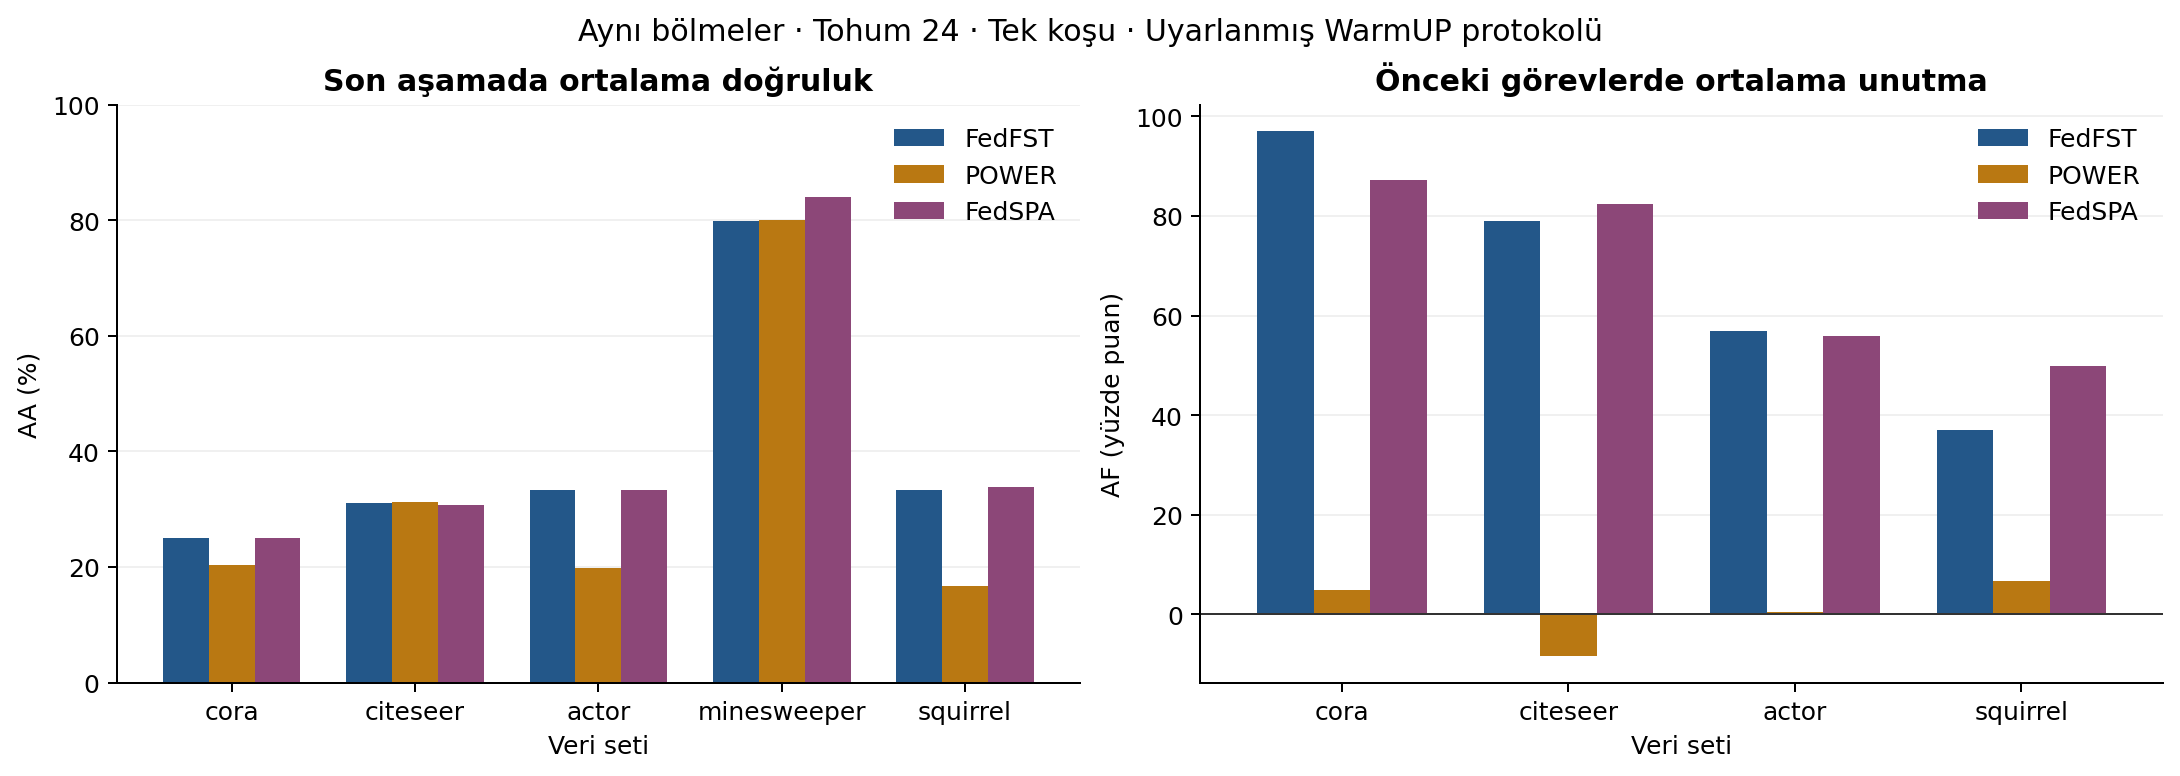

In [33]:
fig,axes = plt.subplots(1,2,figsize=(12,4.2),layout="constrained")
aa.plot.bar(ax=axes[0],color=[COLORS[m] for m in METHODS],rot=0,width=.75)
axes[0].set(title="Son aşamada ortalama doğruluk",ylabel="AA (%)",xlabel="Veri seti",ylim=(0,100))
axes[0].grid(axis="y",alpha=.18); axes[0].set_axisbelow(True)
af.drop(index="minesweeper").plot.bar(ax=axes[1],color=[COLORS[m] for m in METHODS],rot=0,width=.75)
axes[1].set(title="Önceki görevlerde ortalama unutma",ylabel="AF (yüzde puan)",xlabel="Veri seti")
axes[1].axhline(0,color="#333333",lw=.8); axes[1].grid(axis="y",alpha=.18); axes[1].set_axisbelow(True)
for ax in axes: ax.legend(title=None,frameon=False,loc="upper right")
fig.suptitle("Aynı bölmeler · Tohum 24 · Tek koşu · Uyarlanmış WarmUP protokolü")
fig.savefig("comparison.png",dpi=180,bbox_inches="tight")
plt.close(fig)
display(Image(filename="comparison.png"))

### Görevler ilerledikçe bilgi tutma

Her noktada o ana kadar öğrenilen görevlerin AA değeri gösterilir. Eksenler bütün veri
setlerinde aynı doğruluk ölçeğindedir. Minesweeper yalnızca bir nokta içerir.

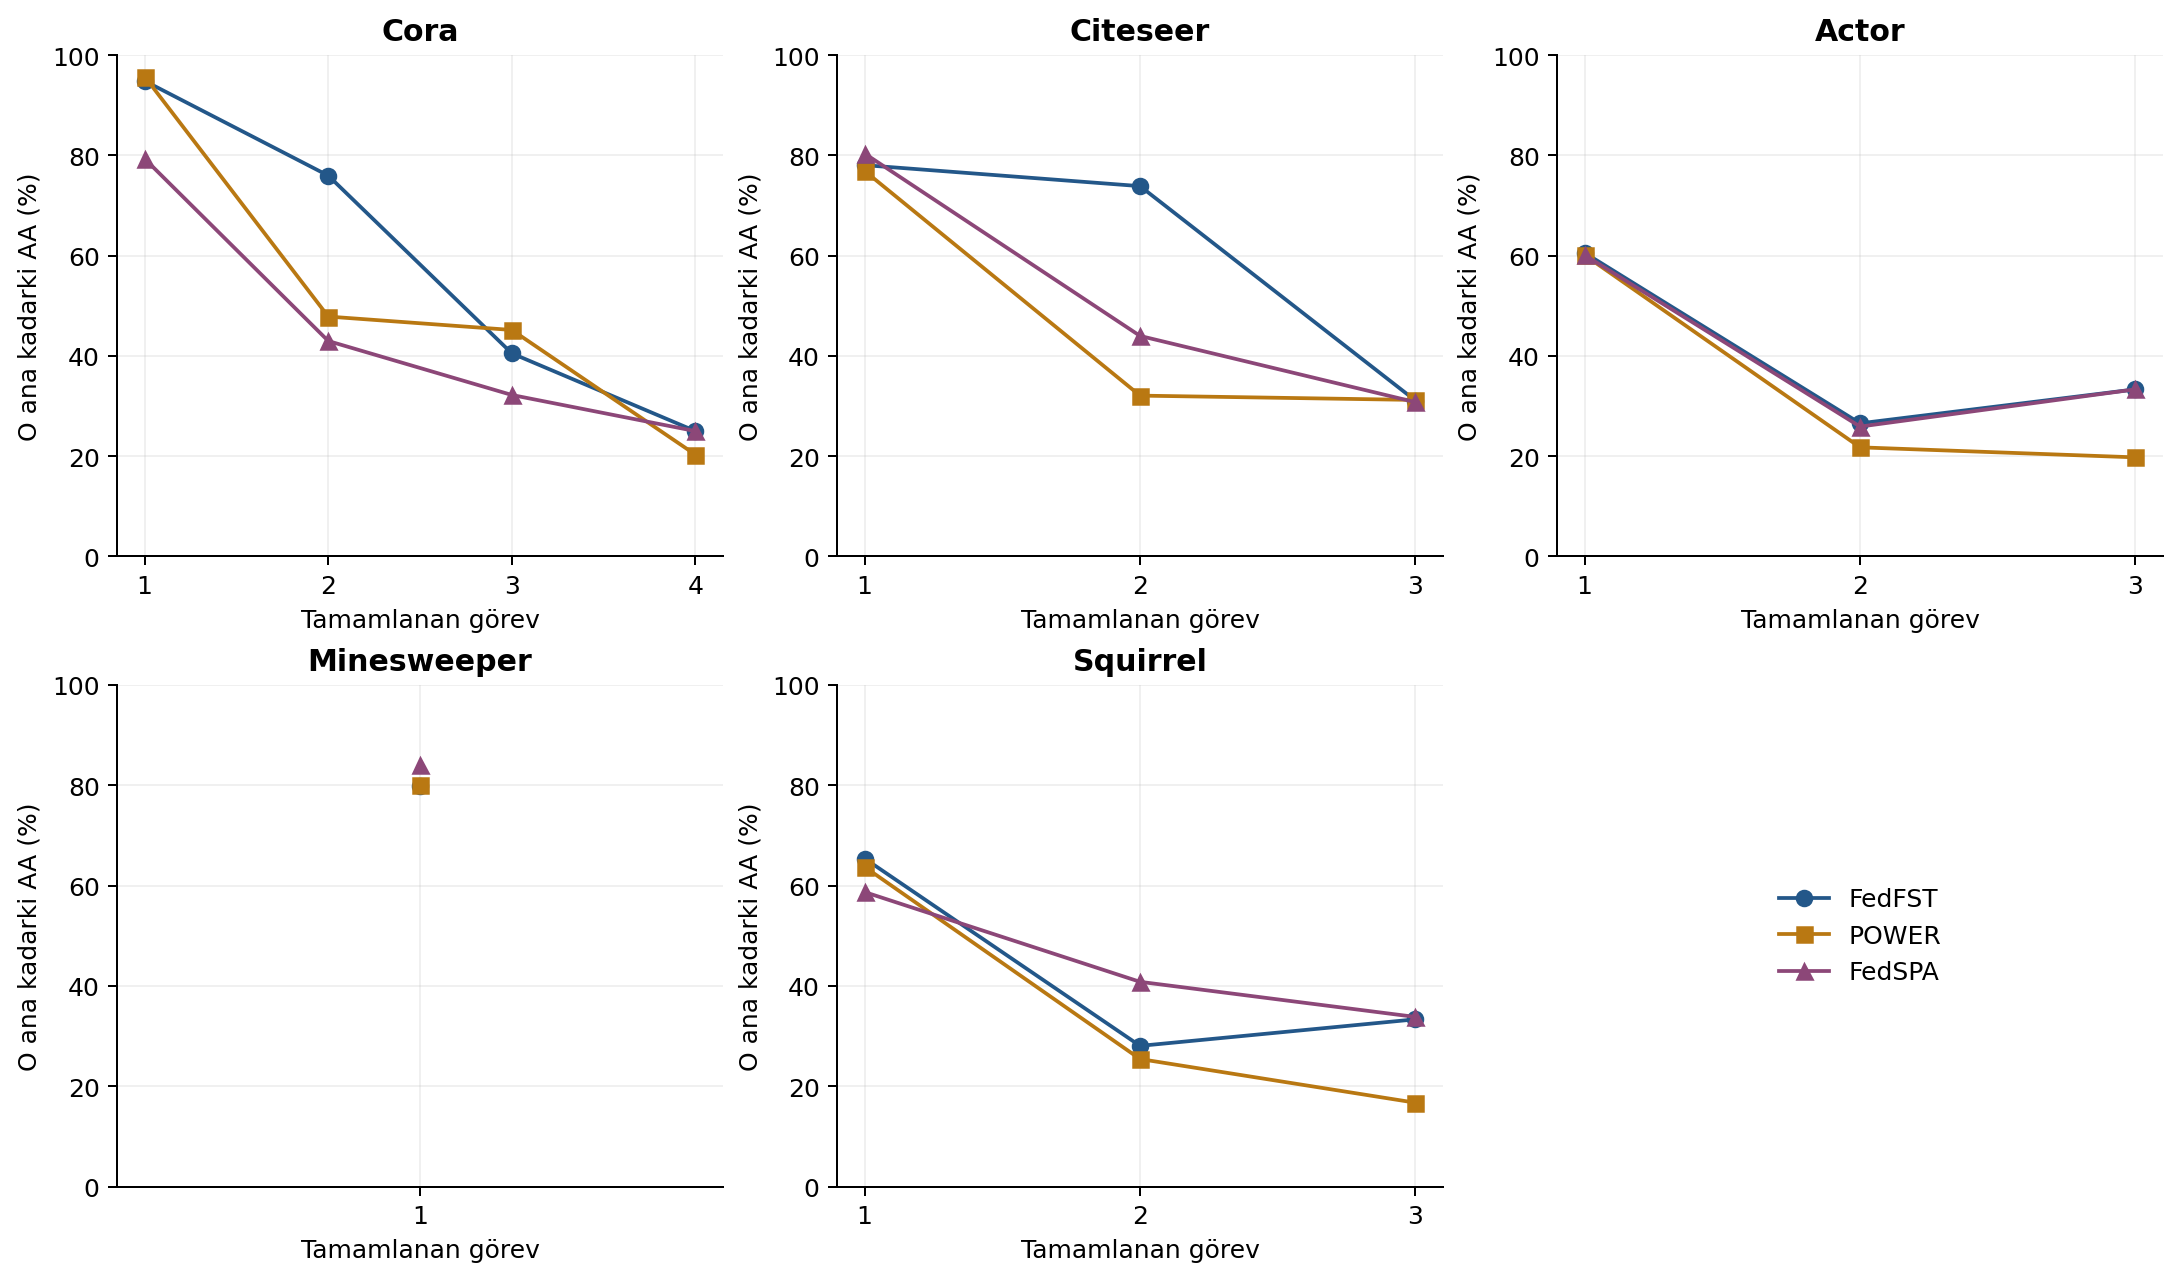

In [34]:
fig,axes = plt.subplots(2,3,figsize=(12,7),layout="constrained")
for ax,dataset in zip(axes.flat,DATASETS):
    for method,marker in zip(METHODS,["o","s","^"]):
        r = next(r for r in records if r["dataset"]==dataset and r["method"]==method)
        matrix = np.array(r["matrix"],dtype=float)
        y = [matrix[t,:t+1].mean() for t in range(len(matrix))]
        ax.plot(range(1,len(y)+1),y,marker=marker,color=COLORS[method],label=method)
    ax.set(title=dataset.title(),xlabel="Tamamlanan görev",ylabel="O ana kadarki AA (%)",ylim=(0,100))
    ax.set_xticks(range(1,len(y)+1)); ax.grid(alpha=.18)
axes.flat[-1].axis("off")
handles,labels=axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles,labels,frameon=False,loc="center")
fig.savefig("task_progress.png",dpi=180,bbox_inches="tight")
plt.close(fig)
display(Image(filename="task_progress.png"))

## 8 Sonuçların yorumlanması

Aşağıdaki özet doğrudan çalıştırılmış sonuçlardan üretilir. Doğruluk ve unutma birlikte
okunmalıdır: son görevdeki yüksek doğruluk önceki görevlerin korunduğunu tek başına göstermez.

In [35]:
for dataset in DATASETS:
    subset=summary[summary.dataset==dataset].sort_values("AA_percent",ascending=False)
    best=subset.iloc[0]
    leaders = " / ".join(subset.loc[np.isclose(subset.AA_percent,best.AA_percent,rtol=0,atol=1e-9),"method"])
    display(Markdown(f"- **{dataset.title()}**: bu tek koşuda en yüksek AA **{leaders}** ile **%{best['AA_percent']:.2f}**."
                     + (" Tek görev olduğu için unutma karşılaştırması yapılamaz." if dataset=="minesweeper" else "")))
display(Markdown("Bu gözlemler tek tohum ve azaltılmış yardımcı eğitim bütçesine aittir. "
                 "FedSPA'nın görev akışına uyarlanması, farklı modeller ve yöntemlere özgü ek eğitim "
                 "maliyetleri karşılaştırmanın sınırlarıdır. Daha güçlü bir değerlendirme için aynı "
                 "protokolde birden fazla tohum, bütçe duyarlılığı ve özgün makale ayarlarıyla ek koşular gerekir."))

- Cora: bu tek koşuda en yüksek AA FedFST / FedSPA ile %25.00.
- Citeseer: bu tek koşuda en yüksek AA POWER ile %31.22.
- Actor: bu tek koşuda en yüksek AA FedFST / FedSPA ile %33.33.
- Minesweeper: bu tek koşuda en yüksek AA FedSPA ile %84.07. Tek görev olduğu için unutma karşılaştırması yapılamaz.
- Squirrel: bu tek koşuda en yüksek AA FedSPA ile %33.81.
Bu gözlemler tek tohum ve azaltılmış yardımcı eğitim bütçesine aittir. FedSPA'nın görev akışına uyarlanması, farklı modeller ve yöntemlere özgü ek eğitim maliyetleri karşılaştırmanın sınırlarıdır. Daha güçlü bir değerlendirme için aynı protokolde birden fazla tohum, bütçe duyarlılığı ve özgün makale ayarlarıyla ek koşular gerekir.


## 9 Çalışma kanıtları ve tekrar çalıştırma

Bu hücre, ham metrikleri, logları, kaynak sürümlerini, ortamı ve uyarlama kodlarını
bir ZIP dosyasına toplar. Sonuç JSON'ları özgün görev matrislerini içerir.
Defterin kendisi **Dosya → İndir → .ipynb indir** ile çıktılarıyla birlikte indirilebilir.
Çıktıların otomatik kaydını kapatan bir Colab ayarı kullanılırsa teslim öncesi açılmalıdır.

Hocalara erişim, defterin paylaş düğmesinden öğrenci tarafından daha sonra verilecektir.

In [36]:
import zipfile
archive = Path("FedFST_Odev2_deney_kanitlari.zip")
paths = [*RESULTS_DIR.glob("*.json"),*Path("logs").glob("*.log"),
         Path("sources/source_manifest.json"),Path("environment.json"),Path("dataset_metadata.json"),
         Path("results_summary.csv"),Path("prepare_sources.py"),Path("experiment_common.py"),Path("run_experiment.py"),
         Path("comparison.png"),Path("task_progress.png")]
with zipfile.ZipFile(archive,"w",zipfile.ZIP_DEFLATED) as z:
    for path in paths:
        if path.exists(): z.write(path,str(path))
print(f"Tamamlandı: {len(records)} deney; kanıt arşivi: {archive} ({archive.stat().st_size/1024:.1f} KB)")
print("Kaynak sürümleri, gerçek metrikler ve ortam bilgisi arşivde kayıtlıdır.")

Tamamlandı: 15 deney; kanıt arşivi: FedFST_Odev2_deney_kanitlari.zip (284.0 KB)
Kaynak sürümleri, gerçek metrikler ve ortam bilgisi arşivde kayıtlıdır.
